In [2]:
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
import torch
from torch import nn

In [3]:
n_train, n_test, num_inputs, batch_size = 20, 100, 200, 5

# 定义真实权重和偏置
true_w = torch.ones((num_inputs, 1)) * 0.01
true_b = 0.05

# 生成训练集和测试集
def synthetic_data(w, b, num_examples):
    X = torch.randn(num_examples, w.shape[0])
    y = X @ w + b
    y += torch.tensor(
        np.random.normal(0, 0.01, size=y.shape),
        dtype=torch.float32
    )
    return X, y

train_features, train_labels = synthetic_data(
    true_w, true_b, n_train
)
test_features, test_labels = synthetic_data(
    true_w, true_b, n_test
)

# 构造 DataLoader
train_iter = DataLoader(
    TensorDataset(train_features, train_labels),
    batch_size=batch_size,
    shuffle=True
)

test_iter = DataLoader(
    TensorDataset(test_features, test_labels),
    batch_size=batch_size,
    shuffle=False
)

初始化模型参数

In [4]:
def init_params():
    w=torch.normal(0,1,size=(num_inputs,1),requires_grad=True)
    b=torch.zeros(1,requires_grad=True)
    return [w,b]

定义L2范数惩罚

In [5]:
def l2_penalty(w):
    return torch.sum(w.pow(2))/2

定义训练代码实现

In [7]:
import torch
import matplotlib.pyplot as plt

def squared_loss(y_hat, y):
    y = y.reshape(y_hat.shape)
    return (y_hat - y) ** 2 / 2

def evaluate_loss(net, data_iter, loss):
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for X, y in data_iter:
            l = loss(net(X), y)
            total_loss += l.sum().item()
            total_samples += y.shape[0]

    return total_loss / total_samples

def train(lambd):
    w, b = init_params()

    net = lambda X: X @ w + b
    loss = squared_loss

    num_epochs, lr = 100, 0.003

    train_losses = []
    test_losses = []
    epochs_list = []

    for epoch in range(num_epochs):
        for X, y in train_iter:
            # 计算原始损失和 L2 正则化项
            l = loss(net(X), y) + lambd * l2_penalty(w)

            # 反向传播
            l.sum().backward()

            # 手动执行 SGD 参数更新
            with torch.no_grad():
                w -= lr * w.grad / batch_size
                b -= lr * b.grad / batch_size

            # 清空梯度，防止下一批次累积
            w.grad.zero_()
            b.grad.zero_()

        if (epoch + 1) % 5 == 0:
            train_loss = evaluate_loss(net, train_iter, loss)
            test_loss = evaluate_loss(net, test_iter, loss)

            epochs_list.append(epoch + 1)
            train_losses.append(train_loss)
            test_losses.append(test_loss)

    # 绘制损失曲线
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_list, train_losses, label="train")
    plt.plot(epochs_list, test_losses, label="test")
    plt.xlabel("epochs")
    plt.ylabel("loss")
    plt.yscale("log")
    plt.xlim(5, num_epochs)
    plt.legend()
    plt.grid(True)
    plt.show()

    print("w 的 L2 范数是：", torch.norm(w).item())

    return w, b

忽略正则化直接训练

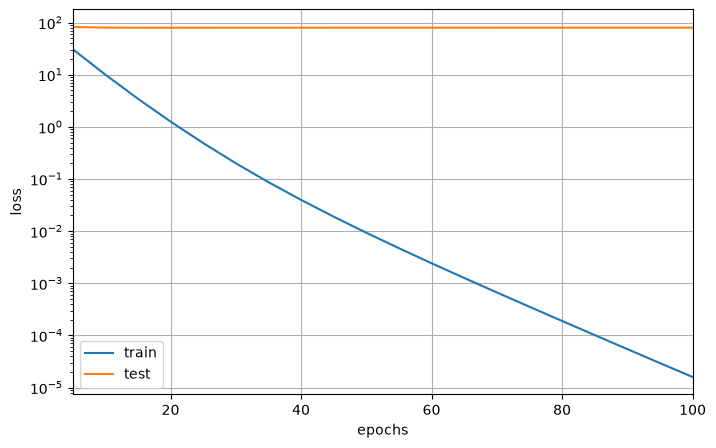

w 的 L2 范数是： 12.514402389526367


(tensor([[ 6.7498e-01],
         [ 1.2418e+00],
         [-1.7486e+00],
         [ 9.3583e-01],
         [ 1.3611e-01],
         [ 1.6255e+00],
         [ 1.0079e+00],
         [ 1.5767e+00],
         [ 6.9574e-01],
         [-1.4868e-01],
         [ 1.5298e+00],
         [-1.1131e-01],
         [ 3.0471e-01],
         [-1.8892e-01],
         [ 1.1876e-01],
         [ 8.5464e-01],
         [-1.4974e-01],
         [-1.3027e+00],
         [ 8.4262e-02],
         [ 1.6027e-01],
         [ 1.0309e+00],
         [-4.7300e-01],
         [-9.0526e-01],
         [ 3.3361e-01],
         [ 1.3872e+00],
         [-2.8159e-01],
         [-2.2219e-01],
         [ 5.4088e-01],
         [-1.2206e+00],
         [-1.0822e-01],
         [ 6.5084e-01],
         [-9.5229e-02],
         [-1.4443e+00],
         [-1.2317e+00],
         [-9.8364e-01],
         [ 3.7386e-01],
         [-8.3397e-01],
         [-8.1038e-05],
         [ 1.8095e-01],
         [ 1.6150e+00],
         [-1.1532e+00],
         [-9.578

In [8]:
train(lambd=0)

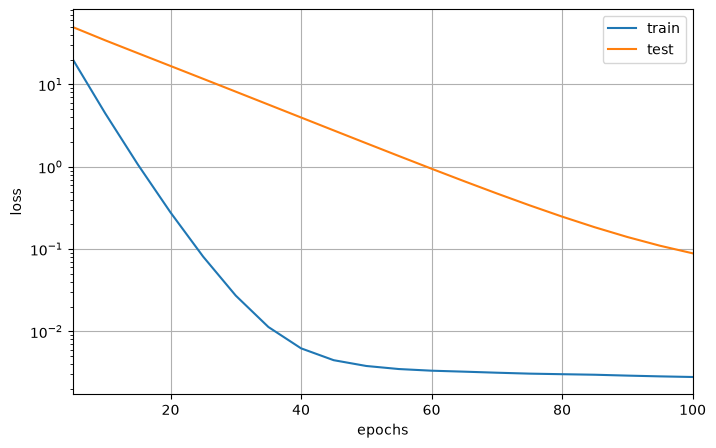

w 的 L2 范数是： 0.35651764273643494


(tensor([[ 0.0269],
         [-0.0212],
         [-0.0216],
         [-0.0065],
         [ 0.0426],
         [-0.0468],
         [-0.0086],
         [ 0.0047],
         [ 0.0155],
         [-0.0466],
         [ 0.0095],
         [ 0.0006],
         [ 0.0504],
         [ 0.0362],
         [ 0.0120],
         [ 0.0416],
         [ 0.0062],
         [ 0.0191],
         [-0.0137],
         [ 0.0109],
         [ 0.0082],
         [ 0.0068],
         [ 0.0116],
         [-0.0236],
         [-0.0224],
         [ 0.0305],
         [ 0.0127],
         [ 0.0164],
         [-0.0038],
         [ 0.0400],
         [ 0.0266],
         [-0.0438],
         [ 0.0339],
         [ 0.0366],
         [-0.0282],
         [ 0.0436],
         [ 0.0189],
         [ 0.0055],
         [-0.0197],
         [-0.0351],
         [ 0.0076],
         [ 0.0050],
         [-0.0376],
         [-0.0082],
         [-0.0002],
         [ 0.0118],
         [-0.0216],
         [-0.0596],
         [-0.0073],
         [-0.0288],


In [9]:
train(lambd=3)

简洁实现

In [10]:
def train_concise(wd):
    net = nn.Sequential(nn.Linear(num_inputs, 1))

    for param in net.parameters():
        param.data.normal_()

    loss = nn.MSELoss(reduction='none')
    num_epochs, lr = 100, 0.003

    # 只对权重进行权重衰减，不对偏置进行衰减
    trainer = torch.optim.SGD([
        {"params": net[0].weight, "weight_decay": wd},
        {"params": net[0].bias}
    ], lr=lr)

    train_losses = []
    test_losses = []
    epochs_list = []

    for epoch in range(num_epochs):
        for X, y in train_iter:
            trainer.zero_grad()

            l = loss(net(X), y)
            l.mean().backward()

            trainer.step()

        if (epoch + 1) % 5 == 0:
            train_loss = evaluate_loss(
                net, train_iter, loss
            )
            test_loss = evaluate_loss(
                net, test_iter, loss
            )

            epochs_list.append(epoch + 1)
            train_losses.append(train_loss)
            test_losses.append(test_loss)

    # 绘制损失曲线
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_list, train_losses, label='train')
    plt.plot(epochs_list, test_losses, label='test')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.yscale('log')
    plt.xlim(5, num_epochs)
    plt.legend()
    plt.grid(True)
    plt.show()

    print('w 的 L2 范数是：', net[0].weight.norm().item())

    return net

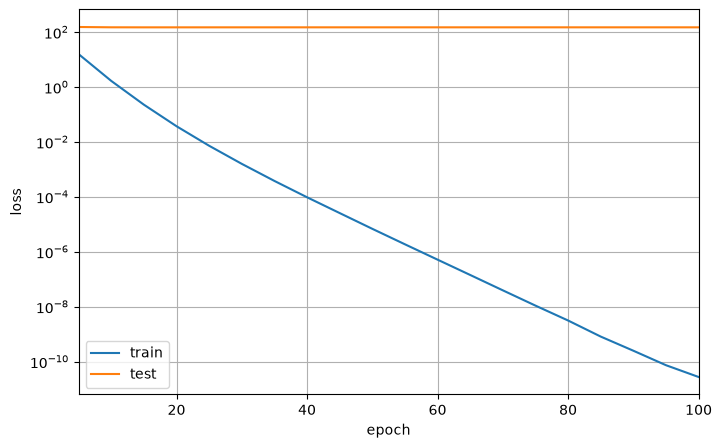

w 的 L2 范数是： 13.542804718017578


Sequential(
  (0): Linear(in_features=200, out_features=1, bias=True)
)

In [11]:
train_concise(0)

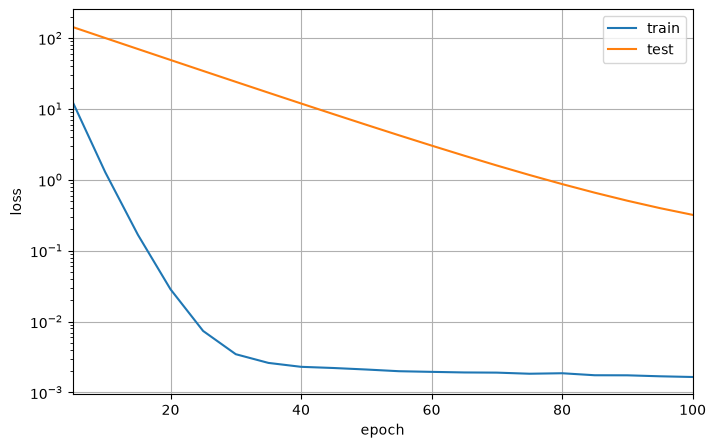

w 的 L2 范数是： 0.3715008497238159


Sequential(
  (0): Linear(in_features=200, out_features=1, bias=True)
)

In [12]:
train_concise(3)